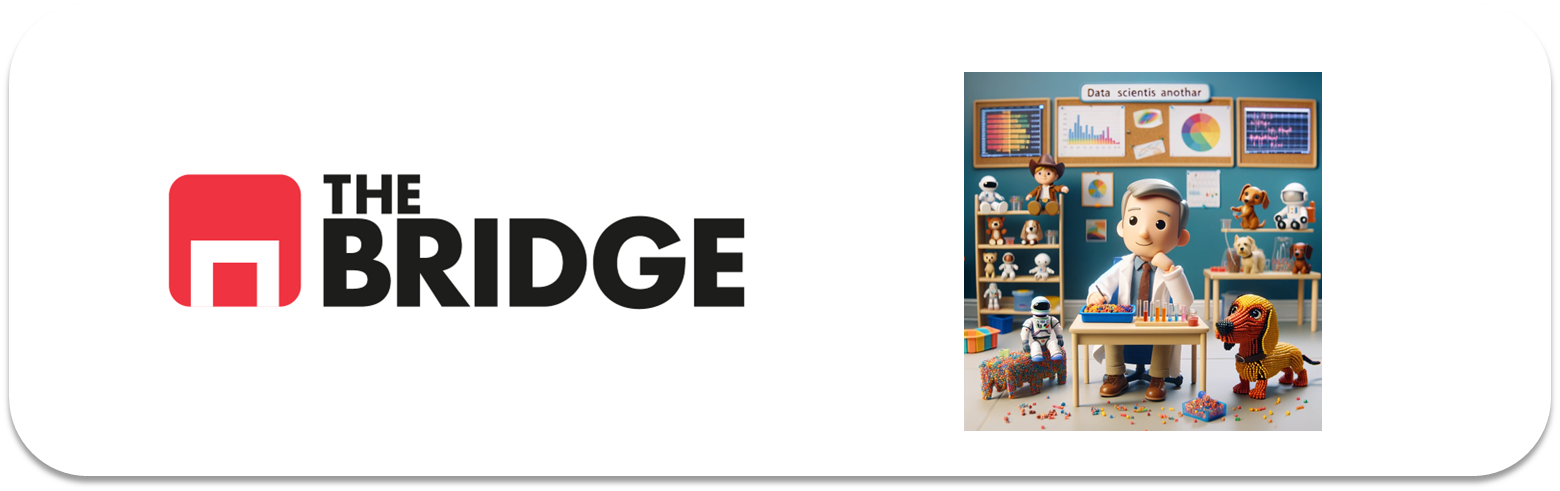

## Data Cleaning: Limpieza básica de datos

En el módulo de EDA aprendimos a **detectar** cosas raras en los datos: nulos, valores extremos, categorías que dominan, tipos mal asignados... En este módulo toca **arreglarlas**.

La limpieza de datos rara vez es glamurosa, pero es donde se va gran parte del tiempo de cualquier proyecto real, y un análisis o un modelo construido sobre datos sucios da conclusiones sucias.

En este primer notebook vemos la limpieza "básica", la que casi cualquier dataset necesita:

1. Examinar los datos
2. Corregir tipos de datos
3. Limpiar texto
4. Recolocar valores que están en la columna equivocada
5. Detectar duplicados (y falsos duplicados)
6. Unificar categorías inconsistentes
7. Convertir texto con formato mixto en números
8. Empaquetar todo en una función reproducible

Los **valores nulos** y los **outliers** tienen su propio notebook cada uno (`02` y `03`).

Trabajaremos con el dataset [Netflix Movies and TV Shows](https://www.kaggle.com/datasets/shivamb/netflix-shows), con el catálogo de películas y series de Netflix.

In [ ]:
import numpy as np
import pandas as pd

netflix = pd.read_csv("../data/netflix_titles.csv")

### #1 Examinar los datos

Antes de tocar nada, miramos. Igual que en el primer contacto del EDA: tamaño, columnas, tipos y unas cuantas filas.

In [ ]:
print(netflix.shape)
netflix.head()

In [ ]:
netflix.info()

Un primer vistazo anotado a las primeras filas ya nos da pistas de lo que habrá que arreglar:

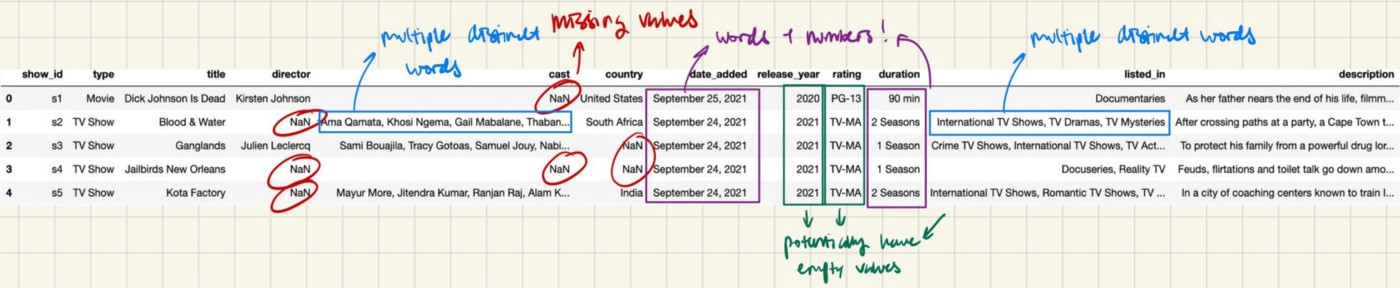

Apuntamos lo que vemos:
* Casi todo es texto (`object`/`str`), incluida `date_added`, que debería ser una fecha.
* `duration` mezcla dos formatos: minutos para películas ("90 min") y temporadas para series ("2 Seasons").
* `country`, `cast`, `director` y `listed_in` pueden contener **varios valores separados por comas**.
* Hay columnas con nulos (los trataremos en el siguiente notebook; aquí solo los tenemos presentes).

In [ ]:
netflix.isna().sum()

### #2 Corregir tipos de datos

`date_added` es texto, así que no podemos ordenar por fecha, filtrar por año ni calcular diferencias. Lo convertimos con `pd.to_datetime`, indicando el formato (`"%B %d, %Y"` = "September 25, 2021").

Usamos `errors="coerce"` para que, si algún valor no encaja con el formato, se convierta en `NaT` (el nulo de las fechas) en lugar de dar un error. Y después **comprobamos** cuántos han fallado:

In [ ]:
fechas = pd.to_datetime(netflix["date_added"], format="%B %d, %Y", errors="coerce")

print("Nulos que ya había en date_added:", netflix["date_added"].isna().sum())
print("Fechas que no se han podido convertir:", fechas.isna().sum())

Había 10 nulos, pero han fallado 98 conversiones. ¿Qué tienen las otras 88? Miremos algunas:

In [ ]:
fallidas = netflix.loc[fechas.isna() & netflix["date_added"].notna(), "date_added"]
fallidas.head().tolist()

¡Un espacio al principio! Invisible al mirar el dataframe, pero suficiente para que el formato no encaje. Esto nos lleva al siguiente paso: limpiar el texto **antes** de convertir tipos.

> **Lección**: `errors="coerce"` es muy cómodo, pero puede esconder problemas. Compara siempre los nulos antes y después de una conversión.

### #3 Limpiar texto

Los problemas más comunes en columnas de texto son los **espacios sobrantes** (al principio o al final) y las **mayúsculas/minúsculas inconsistentes** ("Spain", "spain", "SPAIN"). Para los espacios, `str.strip()`. Lo aplicamos a todas las columnas de texto y contamos cuántos valores cambian:

In [ ]:
columnas_texto = netflix.select_dtypes(include=["object", "string"]).columns

antes = netflix[columnas_texto].copy()
netflix[columnas_texto] = netflix[columnas_texto].apply(lambda col: col.str.strip())

cambios = (antes != netflix[columnas_texto]) & antes.notna()
cambios.sum()[cambios.sum() > 0]

Ahora sí, convertimos la fecha:

In [ ]:
netflix["date_added"] = pd.to_datetime(netflix["date_added"], format="%B %d, %Y", errors="coerce")

print("Fechas nulas tras la conversión:", netflix["date_added"].isna().sum())  # solo los 10 nulos originales
netflix["date_added"].dtype

### #4 Valores en la columna equivocada

Revisar los valores únicos de las categóricas suele destapar sorpresas. Mira `rating` (la calificación por edades):

In [ ]:
netflix["rating"].value_counts()

Hay tres "ratings" que en realidad son duraciones ("74 min", "84 min", "66 min"). Veamos esas filas:

In [ ]:
mask_rating_mal = netflix["rating"].str.contains("min", na=False)
netflix.loc[mask_rating_mal, ["title", "type", "rating", "duration"]]

Son tres películas cuya duración se grabó en la columna `rating`, y por eso `duration` está vacía. Lo arreglamos moviendo el valor a su sitio y dejando el rating como desconocido. (Si conociéramos el rating real, buscándolo en otra fuente, lo pondríamos; es la opción "intenta obtenerlo" que veremos con los nulos.)

In [ ]:
netflix.loc[mask_rating_mal, "duration"] = netflix.loc[mask_rating_mal, "rating"]
netflix.loc[mask_rating_mal, "rating"] = np.nan

netflix.loc[mask_rating_mal, ["title", "type", "rating", "duration"]]

Fíjate en que usamos `netflix.loc[filas, columna] = valor`. Es la forma segura de modificar un dataframe en pandas; otras formas que verás por internet, como `df[col][filas] = valor` o `df[col].fillna(..., inplace=True)`, pueden no modificar nada en las versiones actuales de pandas.

### #5 Duplicados

Hay tres situaciones distintas:

1. **Duplicados exactos**: filas idénticas en todas las columnas. `df.duplicated()`.
2. **Duplicados por clave**: el mismo registro (mismo identificador) aparece varias veces aunque alguna columna difiera. `df.duplicated(subset=[...])`.
3. **Falsos duplicados**: filas iguales que en realidad son registros distintos.

In [ ]:
print("Duplicados exactos:", netflix.duplicated().sum())
print("show_id repetidos:", netflix["show_id"].duplicated().sum())
print("Mismo título y tipo:", netflix.duplicated(subset=["title", "type"]).sum())

No hay filas idénticas ni identificadores repetidos... pero hay un título que aparece dos veces como película. Veamos cuál:

In [ ]:
netflix[netflix.duplicated(subset=["title", "type"], keep=False)]

Es la misma película (mismo director, año, país, duración y fecha de alta) con **dos `show_id` distintos**: un duplicado por clave de negocio. Y fíjate en por qué no lo habíamos visto antes: en el fichero original, uno de los títulos terminaba en un espacio duro invisible (` `), así que para pandas eran textos distintos. **Solo apareció después de limpiar el texto**: por eso la limpieza de texto va antes de buscar duplicados.

Nos quedamos con la primera aparición:

In [ ]:
netflix = netflix.drop_duplicates(subset=["title", "type", "director", "release_year"], keep="first")
print("Filas:", len(netflix))

Ahora el tercer caso, el más traicionero. Mira el Titanic que usamos en EDA:

In [ ]:
titanic = pd.read_csv("../data/titanic.csv")

print("Filas 'duplicadas' en el Titanic:", titanic.duplicated().sum())
titanic[titanic.duplicated(keep=False)].sort_values(["pclass", "sex", "age"]).head(6)

¿Borramos 107 pasajeros? **No.** Este dataset no tiene nombre ni número de billete. Las dos primeras filas son dos mujeres de 24 años, de 1ª clase, que embarcaron en Cherburgo y pagaron exactamente lo mismo: seguramente viajaban juntas con el mismo billete, pero son **dos personas**. Lo mismo con los dos hombres de 1ª sin edad registrada, y así con el resto.

> **Regla**: solo eliminamos duplicados cuando sabemos que representan el **mismo registro** (porque tienen el mismo identificador o porque sabemos cómo se generaron los datos). Sin identificador, investiga antes de borrar.

Para el caso en que sí hay que eliminarlos, la herramienta es `drop_duplicates`:

In [ ]:
ejemplo = pd.DataFrame({"id": [1, 2, 2, 3], "valor": [10, 20, 20, 30]})
ejemplo.drop_duplicates()                       # quita filas exactas repetidas
# ejemplo.drop_duplicates(subset=["id"], keep="last")  # o por clave, quedándose con la última

### #6 Categorías inconsistentes

`country` tiene varios países por fila. Para ver qué valores hay realmente, separamos por comas y "explotamos" la lista en filas (`explode`):

In [ ]:
paises = netflix["country"].str.split(",").explode().str.strip()

print("Países distintos:", paises.nunique())
print("Valores vacíos (por comas sobrantes):", (paises == "").sum())
sorted(p for p in paises.dropna().unique() if "Germany" in p or "Soviet" in p or "Russia" in p)

Encontramos dos tipos de problema:
* **Valores vacíos**, porque algunas filas terminan en coma ("France, ").
* **Nombres distintos para lo mismo** (o casi): "West Germany" / "East Germany" / "Germany", "Soviet Union" / "Russia".

Lo segundo es una **decisión de negocio**, no técnica: para un análisis del catálogo actual por país tiene sentido unificarlos; para un estudio histórico, no. Aquí los unificamos y **lo dejamos documentado**:

In [ ]:
UNIFICAR_PAISES = {"West Germany": "Germany", "East Germany": "Germany", "Soviet Union": "Russia"}

def limpiar_lista_paises(texto):
    if pd.isna(texto):
        return texto
    paises = [p.strip() for p in texto.split(",")]
    paises = [UNIFICAR_PAISES.get(p, p) for p in paises if p != ""]
    return ", ".join(dict.fromkeys(paises))   # dict.fromkeys quita repetidos manteniendo el orden

netflix["country"] = netflix["country"].apply(limpiar_lista_paises)

paises = netflix["country"].str.split(", ").explode()
print("Países distintos ahora:", paises.nunique(), "| vacíos:", (paises == "").sum())

Algo parecido pasa en `rating`: **UR** (*Unrated*) y **NR** (*Not Rated*) significan lo mismo. Unificamos en la más frecuente:

In [ ]:
netflix["rating"] = netflix["rating"].replace({"UR": "NR"})
netflix["rating"].value_counts().tail()

### #7 Texto con formato mixto → números

`duration` guarda dos cosas distintas según el tipo de título. Lo correcto es separarlas en dos columnas numéricas, cada una con su unidad. Con `str.extract` y una expresión regular sacamos el número (`\d+` = uno o más dígitos):

In [ ]:
netflix[["type", "duration"]].drop_duplicates("type")

In [ ]:
numero = netflix["duration"].str.extract(r"(\d+)")[0].astype("Int64")

es_peli = netflix["type"] == "Movie"
netflix["duracion_min"] = numero.where(es_peli)       # solo para películas
netflix["temporadas"] = numero.where(~es_peli)        # solo para series

netflix[["type", "duration", "duracion_min", "temporadas"]].sample(6, random_state=1)

Usamos el tipo `"Int64"` (con mayúscula), el entero de pandas que **admite nulos**. Con el `int64` normal no podríamos tener enteros y `NaN` en la misma columna (pandas los pasaría a decimales).

Comprobamos que la separación es coherente: ninguna película debería tener temporadas, y cada película debería tener duración:

In [ ]:
print("Películas con temporadas:", netflix.loc[es_peli, "temporadas"].notna().sum())
print("Películas sin duración:", netflix.loc[es_peli, "duracion_min"].isna().sum())
netflix.groupby("type")[["duracion_min", "temporadas"]].describe().T

### #8 Todo junto: una función reproducible

Hemos ido limpiando paso a paso, probando y comprobando. Pero en un proyecto real los datos se actualizan (el mes que viene Netflix tendrá más títulos) y no queremos repetir todo a mano. La buena práctica es **empaquetar la limpieza en una función** que parta de los datos originales:

In [ ]:
def limpiar_netflix(df):
    """Limpieza básica del dataset de Netflix. Devuelve una copia limpia."""
    df = df.copy()

    # Texto: quitar espacios sobrantes
    columnas_texto = df.select_dtypes(include=["object", "string"]).columns
    df[columnas_texto] = df[columnas_texto].apply(lambda col: col.str.strip())

    # Tipos: fecha
    df["date_added"] = pd.to_datetime(df["date_added"], format="%B %d, %Y", errors="coerce")

    # Duraciones guardadas por error en rating
    mal = df["rating"].str.contains("min", na=False)
    df.loc[mal, "duration"] = df.loc[mal, "rating"]
    df.loc[mal, "rating"] = np.nan

    # Duplicados por clave de negocio (tras limpiar el texto)
    df = df.drop_duplicates(subset=["title", "type", "director", "release_year"], keep="first")

    # Categorías inconsistentes
    df["country"] = df["country"].apply(limpiar_lista_paises)
    df["rating"] = df["rating"].replace({"UR": "NR"})

    # Duración -> dos columnas numéricas
    numero = df["duration"].str.extract(r"(\d+)")[0].astype("Int64")
    es_peli = df["type"] == "Movie"
    df["duracion_min"] = numero.where(es_peli)
    df["temporadas"] = numero.where(~es_peli)
    return df


netflix_limpio = limpiar_netflix(pd.read_csv("../data/netflix_titles.csv"))
netflix_limpio.info()

Ventajas:
* **Reproducible**: cualquiera (incluido tú dentro de tres meses) obtiene el mismo resultado partiendo del fichero original.
* **Documentado**: la función es la lista de decisiones que hemos tomado.
* **Nunca modificamos el fichero original**: si nos equivocamos, volvemos a empezar desde él.

### Resumen

Checklist de limpieza básica:

| Paso | Pregunta | Herramientas |
|---|---|---|
| Examinar | ¿Qué hay y qué pinta tiene? | `shape`, `info()`, `head()`, `isna().sum()` |
| Tipos | ¿Cada columna tiene el tipo que le corresponde? | `pd.to_datetime`, `astype`, `pd.to_numeric(errors="coerce")` |
| Texto | ¿Espacios, mayúsculas, caracteres raros? | `str.strip()`, `str.lower()`, `str.replace()` |
| Valores fuera de sitio | ¿Hay valores que no corresponden a la columna? | `value_counts()`, `str.contains()`, `.loc` |
| Duplicados | ¿Son el mismo registro de verdad? (busca también por clave de negocio, después de limpiar texto) | `duplicated()`, `drop_duplicates()` |
| Categorías | ¿Hay nombres distintos para lo mismo? | `value_counts()`, `replace()`, `explode()` |
| Formatos mixtos | ¿Una columna guarda varias cosas? | `str.extract()`, `where()`, `"Int64"` |
| Reproducibilidad | ¿Puedo repetirlo desde el original? | Una función `limpiar_...(df)` |

Y dos hábitos: **comprobar después de cada cambio** (contar nulos, únicos, filas) y **documentar las decisiones** que no son puramente técnicas.

**Siguiente notebook:** `02_Valores_Nulos`.